# 01 — Data Exploration: Jena Climate (Temperature)

**Project:** Time-Series Data Analysis Through a Natural HCI Interface  
**Goal:** load, document, and explore the temperature time-series dataset before building the pipeline.

> **Kernel:** pick **Python (tshci - time_series_hci)** from the kernel menu — it has pandas/scikit-learn installed.

## Contents
1. Dataset description
2. Load the data
3. Parse timestamps & set the time index
4. Inspect structure
5. Missing data & sentinel values
6. Descriptive statistics
7. Temperature over time
8. Multi-sensor relationships
9. Next steps

## 1. Dataset description

**Jena Climate (2009–2016)** — weather readings every **10 minutes**, ~420,000 rows, 14 sensor columns. Time-indexed and multi-sensor — ideal for behaviour analysis, anomaly detection, and multi-sensor reasoning.

| Column | Meaning |
| --- | --- |
| `Date Time` | timestamp (every 10 min) |
| `p (mbar)` | atmospheric pressure |
| `T (degC)` | **air temperature** (primary target) |
| `Tpot (K)` | potential temperature |
| `Tdew (degC)` | dew-point temperature |
| `rh (%)` | relative humidity |
| `VPmax/VPact/VPdef (mbar)` | vapour pressure (saturation / actual / deficit) |
| `sh (g/kg)`, `H2OC (mmol/mol)` | humidity / water-vapour concentration |
| `rho (g/m**3)` | air density |
| `wv`, `max. wv (m/s)`, `wd (deg)` | wind speed, gust, direction |

## 2. Load the data

The path is resolved by searching upward for `data/jena_climate_2009_2016.csv`, so the notebook works no matter where Jupyter was launched.

In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

def find_data(name="jena_climate_2009_2016.csv"):
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "data" / name
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"{name} not found; run this notebook from inside the repo.")

DATA_PATH = find_data()
print("Using:", DATA_PATH)
df = pd.read_csv(DATA_PATH)
print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Using: /home/saizer/Documents/Msc_project/code/data/jena_climate_2009_2016.csv
Loaded 420,551 rows x 15 columns


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


## 3. Parse timestamps & set the time index

`Date Time` is `DD.MM.YYYY HH:MM:SS`. We convert to a datetime index so resampling, rolling stats, and decomposition all work correctly.

In [16]:
df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")
df = df.set_index("Date Time").sort_index()
print("Time range:", df.index.min(), "->", df.index.max())
print("Most common interval:", df.index.to_series().diff().mode()[0])

Time range: 2009-01-01 00:10:00 -> 2017-01-01 00:00:00
Most common interval: 0 days 00:10:00


## 4. Inspect structure

In [17]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 420551 entries, 2009-01-01 00:10:00 to 2017-01-01 00:00:00
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   p (mbar)         420551 non-null  float64
 1   T (degC)         420551 non-null  float64
 2   Tpot (K)         420551 non-null  float64
 3   Tdew (degC)      420551 non-null  float64
 4   rh (%)           420551 non-null  float64
 5   VPmax (mbar)     420551 non-null  float64
 6   VPact (mbar)     420551 non-null  float64
 7   VPdef (mbar)     420551 non-null  float64
 8   sh (g/kg)        420551 non-null  float64
 9   H2OC (mmol/mol)  420551 non-null  float64
 10  rho (g/m**3)     420551 non-null  float64
 11  wv (m/s)         420551 non-null  float64
 12  max. wv (m/s)    420551 non-null  float64
 13  wd (deg)         420551 non-null  float64
dtypes: float64(14)
memory usage: 48.1 MB


## 5. Missing data & sentinel values

There are no NaNs, **but** the wind columns use `-9999` as a sentinel for a failed reading — a real data-quality issue. We detect it here; `src/preprocess.py` converts these to NaN and interpolates them.

In [18]:
print("NaNs per column:")
print(df.isna().sum()[lambda s: s > 0] if df.isna().any().any() else "None")
print("\n-9999 sentinel readings per column:")
print((df == -9999.0).sum()[lambda s: s > 0])

NaNs per column:
None

-9999 sentinel readings per column:
wv (m/s)         18
max. wv (m/s)    20
dtype: int64


## 6. Descriptive statistics (temperature focus)

In [19]:
temp = df["T (degC)"]
print(f"Temperature  min={temp.min():.2f}  max={temp.max():.2f}  "
      f"mean={temp.mean():.2f}  std={temp.std():.2f} degC")
print("Coldest at:", temp.idxmin(), "| Warmest at:", temp.idxmax())
df.describe().T

Temperature  min=-23.01  max=37.28  mean=9.45  std=8.42 degC
Coldest at: 2009-01-07 03:10:00 | Warmest at: 2015-07-04 16:00:00


,count,mean,std,min,25%,50%,75%,max
p (mbar),420551.0,989.212776,8.358481,913.60,984.20,989.58,994.72,1015.35
T (degC),420551.0,9.450147,8.423365,-23.01,3.36,9.42,15.47,37.28
Tpot (K),420551.0,283.492743,8.504471,250.60,277.43,283.47,289.53,311.34
Tdew (degC),420551.0,4.955854,6.730674,-25.01,0.24,5.22,10.07,23.11
rh (%),420551.0,76.008259,16.476175,12.95,65.21,79.30,89.40,100.00
VPmax (mbar),420551.0,13.576251,7.739020,0.95,7.78,11.82,17.60,63.77
VPact (mbar),420551.0,9.533756,4.184164,0.79,6.21,8.86,12.35,28.32
VPdef (mbar),420551.0,4.042412,4.896851,0.00,0.87,2.19,5.30,46.01
sh (g/kg),420551.0,6.022408,2.656139,0.50,3.92,5.59,7.80,18.13
H2OC (mmol/mol),420551.0,9.640223,4.235395,0.80,6.29,8.96,12.49,28.82


## 7. Temperature over time (daily mean)

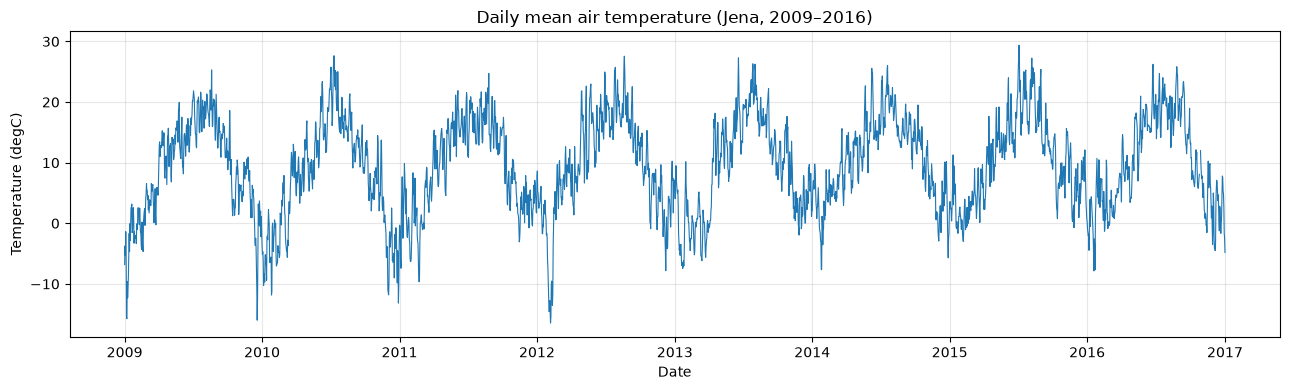

In [20]:
daily_temp = temp.resample("D").mean()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily_temp.index, daily_temp.values, linewidth=0.8)
ax.set_title("Daily mean air temperature (Jena, 2009–2016)")
ax.set_xlabel("Date"); ax.set_ylabel("Temperature (degC)"); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 8. Multi-sensor relationships

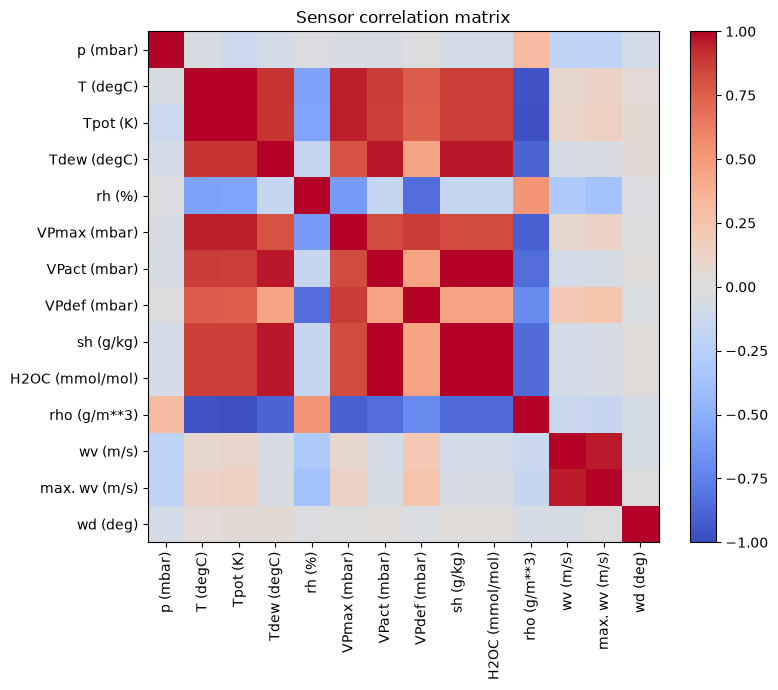

Strongest correlations with temperature:
Tpot (K)           0.996827
VPmax (mbar)       0.951113
Tdew (degC)        0.895708
VPact (mbar)       0.867673
H2OC (mmol/mol)    0.867177
sh (g/kg)          0.866755
VPdef (mbar)       0.761744
max. wv (m/s)      0.125164
wv (m/s)           0.088666
wd (deg)           0.038732
p (mbar)          -0.045375
rh (%)            -0.572416
rho (g/m**3)      -0.963410
Name: T (degC), dtype: float64


In [21]:
# replace the -9999 sentinels before correlating so wind isn't distorted
clean = df.replace(-9999.0, np.nan).interpolate(limit_direction="both")
corr = clean.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns))); ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); ax.set_title("Sensor correlation matrix")
plt.tight_layout(); plt.show()
print("Strongest correlations with temperature:")
print(corr["T (degC)"].drop("T (degC)").sort_values(ascending=False))

## 9. Next steps
- **Phase 1:** cleaning/indexing lives in `src/preprocess.py` (done — also handles the `-9999` sentinels).
- **Phase 2:** rolling stats + STL decomposition in `src/analysis.py` (done).
- See **`03_methods_demo.ipynb`** for anomaly detection, clustering, and the query engine explained and run.